# **Лабораторная работа**
*Naumov Anton (Any0019)*

*To contact me in telegram: @any0019*

В данном задании вашей задачей будет построить и обучить модель CycleGAN для задачи Img2Img.

---

Про задачу __Img2Img__:

- У вас есть 2 множества изображений ($A$ и $B$)
- Ваша задача - научиться превращать изображения из множества $A$ в изображения из множества $B$ и наоборот
- Бывают paired и unpaired множества
- В случае __paired__ множеств - для каждого изображения из $A$ существует конкретное изображение из $B$, в которое оно должно перейти (и наоборот). Примером такой пары множеств может быть (а) спутниковая фотграфия местности vs схематическая карта местности , (б) фотография фасада здания vs схема фасада здания , ...
- В случае __unpaired__ множеств - между множествами нет конкретных пар. Примером такой пары множеств может быть (а) фотографии с лошадьми vs фотографии с зебрами , (б) фотографии vs рисунки конкретного художника , ...

---

Про модель __CycleGAN__:

- Модель придумана для задачи Img2Img (в первую очередь unpaired версии) и основана на концепции GAN-ов
- В модели есть 2 генератора: $G_{A -> B}$ (задача которого - принимая на вход изображение из множества $A$ переводить его в изображение из множества $B$) и $G_{B -> A}$ (аналогично в другую сторону)
- Надо отметить что на вход генераторы не получают никакую дополнительную случайность, что делает обучение таких моделей проще
- В модели так же есть 2 дискриминатора: $D_{A}$ (задача которого - отличать реальные изображения из $A$ от сгенерированных с помощью $G_{B -> A}$ изображений) и $D_{B}$ (аналогично для $B$)
- Функцией ошибки будет, как и для GAN-ов, minmax игра между генераторами и дискриминаторами, но к ошибке генераторов добавится ещё и, так называемый, `cycle consistency loss`, который проверяет, что после двойного перехода изображения не меняются $G_{B -> A} \big( G_{A -> B} ( a ) \big) = a ; \forall a \in A$ и $G_{A -> B} \big( G_{B -> A} ( b ) \big) = b ; \forall b \in B$
- Так же можно добавлять или нет штраф за то, чтобы $G_{B -> A}$ не меняла изображения из $A$ и наоборот $G_{A -> B}$ не меняла изображения из $B$
- Оригинальная статья: https://arxiv.org/pdf/1703.10593.pdf

---

Ваша задача - ноутбук разбит на несколько частей, каждая со своими баллами

1. __Подготовка данных__ _(2 балла)_ --> требуется выбрать датасет для обучения (дано несколько на выбор) и составить пайплайн подготовки данных
2. __Составление модели__ _(6 баллов)_ --> требуется собрать нейросеть _(3 балла)_ и создать функции ошибки _(3 балла)_
3. __Подготовка обучения__ _(2 балла)_ --> требуется написать шаги обучения и валидации, визуализацию, а так же полный цикл обучения
4. __Обучение__ _(2 балла)_ --> требуется обучить модель
5. __Сбор своего датасета и обучение модели на нём__ _(3 балла)_ --> требуется собрать свой датасет и обучить на нём модель

***За наиболее интересные и качественные решения в пункте 5 так же предусмотрены дополнительные баллы***

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader

from torchvision import datasets, transforms as tr

import numpy as np

import matplotlib.pyplot as plt
%matplotlib inline

# Для тёмной темы jupyter - уберите если не нужно
plt.style.use('dark_background')

from tqdm.auto import tqdm, trange

import os
import sys
import requests
import cv2

from dataclasses import dataclass

device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

# 1. Подготовка данных (___2 балла___)

## 1.1 Выбор и скачивание датасета

In [2]:
# dataset_folder = "../../data"
# num_images_per_split = 5

# os.environ["dataset_folder"] = dataset_folder
# !mkdir -p {dataset_folder}

# # В этом цикле каждый из предложенных датасетов
# #  - скачивается
# #  - распаковывается
# #  - отрисовывается + meta
# #  - удаляется

# # Предлагается посмотреть на все предложенные варианты датасетов и затем оставить один,
# #  с которым захочется работать больше всего - закомментируйте (или удалите) все, кроме
# #  выбранного, а так же закомментируйте строчки с удалением скачанного датасета
# for dataset_name in [
#     # Unpaired
#     "apple2orange",
#     "summer2winter_yosemite",
#     "horse2zebra",
#     "monet2photo",
#     "cezanne2photo",
#     "ukiyoe2photo",
#     "vangogh2photo",
#     # Paired
#     "maps",
#     "facades",
# ]:
#     print(f"Dataset '{dataset_name}'")
#     url = f"http://efrosgans.eecs.berkeley.edu/cyclegan/datasets/{dataset_name}.zip"
#     download_path = os.path.join(dataset_folder, f"{dataset_name}.zip")
#     target_folder = os.path.join(dataset_folder, dataset_name)
    
#     # Чтобы bash вызовы знали соответствующие переменные
#     os.environ["url"] = url
#     os.environ["download_path"] = download_path
#     os.environ["target_folder"] = target_folder
    
#     print("Loading zip file...", end="")
#     # Проверяем что нет такого загруженого файла
#     if not os.path.isfile(download_path) or os.path.exists(target_folder):
#         # # Можно загрузить через requests библиотеку
#         # response = requests.get(url)
#         # open(download_path, "wb").write(response.content)
        
#         # Можно загрузить через wget
#         !wget {url} -O {download_path}
#     print(" --> done!")
    
#     print("Unziping...", end="")
#     # Распаковываем
#     if os.path.exists(target_folder):
#         !rm -r {target_folder}
#     !mkdir -p {dataset_folder}
#     !unzip -qq {download_path} -d {dataset_folder}
#     print(" --> done!")
    
#     # Удаляем zip-файл
#     !rm {download_path}
    
#     # Meta + Отрисовка
#     print(f"Provided splits: {os.listdir(target_folder)}")
#     # Удобный способ быстро получить датасет картинок с лэйблами, если картинки разложены по папкам в формате:
#     # root_folder/label_name/img.jpg
#     # (в нашем случае нет лэйблов, но картинки разложены в таком же формате, просто вместо label_name идёт
#     #  split_name: trainA/testA/trainB/testB)
#     dataset = datasets.ImageFolder(target_folder)

#     inds_to_show = {i: [] for i, _ in enumerate(dataset.classes)}
#     classes_full = 0
#     for dataset_ind in range(len(dataset)):
#         _, split_ind = dataset[dataset_ind]
#         if len(inds_to_show[split_ind]) == num_images_per_split:
#             continue
#         inds_to_show[split_ind].append(dataset_ind)
#         if len(inds_to_show[split_ind]) == num_images_per_split:
#             classes_full += 1
#         if classes_full == len(dataset.classes):
#             break

#     for split_name in sorted(dataset.classes):
#         split_ind = dataset.class_to_idx[split_name]
#         print(f"Split '{split_name}' of dataset '{dataset_name}'", end="")
#         split_folder = os.path.join(target_folder, split_name)
#         print(f" --> size: {len(os.listdir(split_folder))}")

#         plt.subplots(1, num_images_per_split, figsize=(5 * num_images_per_split, 5))
#         plt.suptitle(f"{dataset_name} ~ {split_name}", y=0.95)
#         for i, dataset_ind in enumerate(inds_to_show[split_ind]):
#             plt.subplot(1, num_images_per_split, i + 1)
#             plt.imshow(dataset[dataset_ind][0])
#             plt.xticks([])
#             plt.yticks([])
#         plt.show()
    
#     # Удаляем скачанный датасет
#     # !rm -r {target_folder}
    
#     print("\n----------------------------\n")

## 1.2 Dataset и Transforms

В папке `target_folder` находятся несколько папок со сплитами для соответствующего датасета, в каждой папке сплита находятся сами `.jpg` изображения.

Давайте составим их в удобном для нас виде в отдельные датасеты для каждого сплита без лэйблов.

Для получения картинок можно использовать 
```python
cv2.imread(img_path)[:, :, ::-1]  # каналы записаны в обратном порядке
```

In [3]:
from pathlib import Path

# Выбранный выше и скачанный датасет
dataset_directory = Path("../../data")
dataset_name = Path("horse2zebra")
target_directory = dataset_directory / dataset_name

# Класс для датасета изображений без лэйблов с применением трансформов
class ImageDatasetNoLabel(Dataset):
    def __init__(self, directory : Path, transforms=None):
        super(ImageDatasetNoLabel).__init__()
        self.files = []
        self.transform = transforms
        for file in directory.iterdir():
            if file.is_file():
                self.files.append(file.absolute())

    def __getitem__(self, index):
        image = cv2.imread(self.files[index])[:, :, ::-1]
        if self.transform is not None:
            image = self.transform(image)
        return image
    
    def __len__(self):
        return len(self.files)

# Удобный класс для хранения всех наших датасетов
@dataclass
class DatasetsClass:
    train_a: ImageDatasetNoLabel
    train_b: ImageDatasetNoLabel
    test_a: ImageDatasetNoLabel
    test_b: ImageDatasetNoLabel


# Все датасеты без трансформов - чтобы посчитать статистики
ds = DatasetsClass(
    train_a=ImageDatasetNoLabel(target_directory / Path("trainA")),
    train_b=ImageDatasetNoLabel(target_directory / Path("trainB")),
    test_a=ImageDatasetNoLabel(target_directory / Path("testA")),
    test_b=ImageDatasetNoLabel(target_directory / Path("testB")),
)

In [4]:
def get_channel_statistics(_):
    """
    Функция для получения поканальных статистик (среднее и отклонение) по датасету
    Всегда возвращает 0.5 в соответствии с рекомендациями в чате
    """
    return np.array([0.5, 0.5, 0.5]), np.array([0.5, 0.5, 0.5])

# Поканальное среднее и отклонение для A
channel_mean_a, channel_std_a = get_channel_statistics(ds.train_a)
print(channel_mean_a, channel_std_a)

# Поканальное среднее и отклонение для B
channel_mean_b, channel_std_b = get_channel_statistics(ds.train_b)
print(channel_mean_b, channel_std_b)

[0.5 0.5 0.5] [0.5 0.5 0.5]
[0.5 0.5 0.5] [0.5 0.5 0.5]


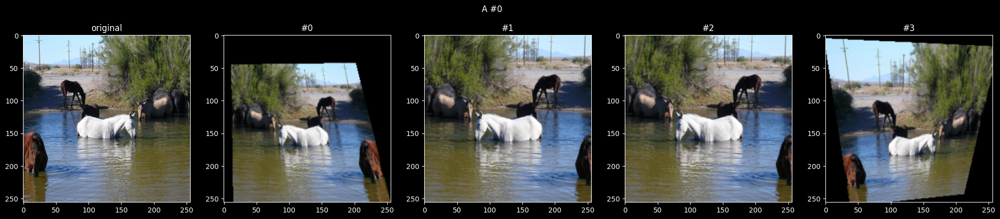

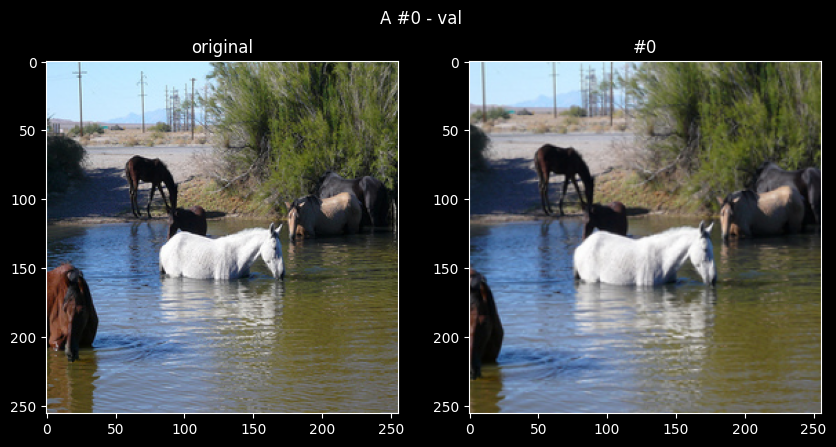

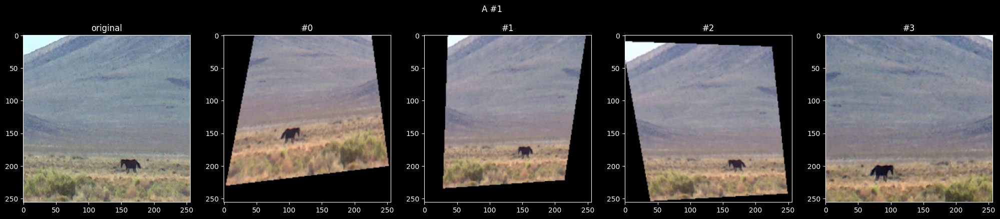

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.0000000000000002].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.0000000000000002].


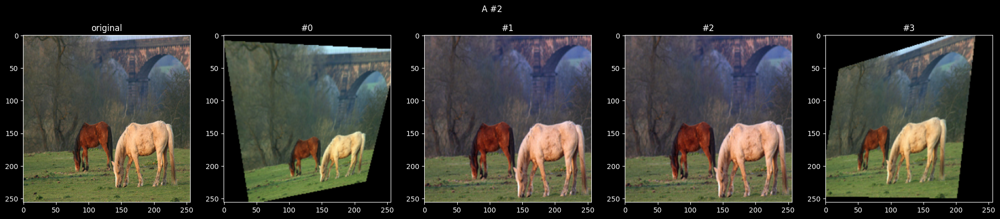

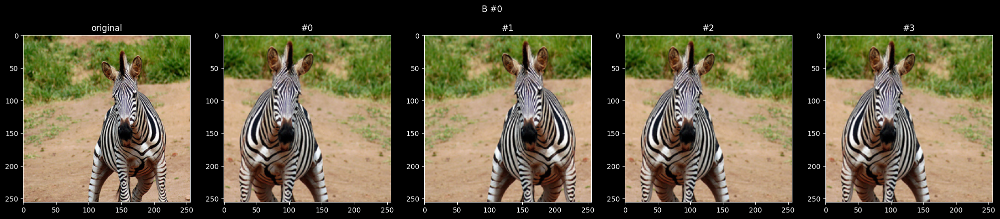

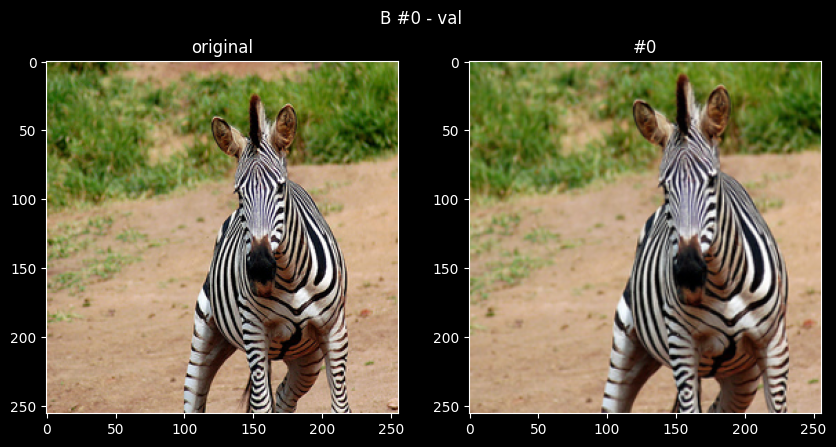

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.0000000000000002].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.0000000000000002].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.0000000000000002].


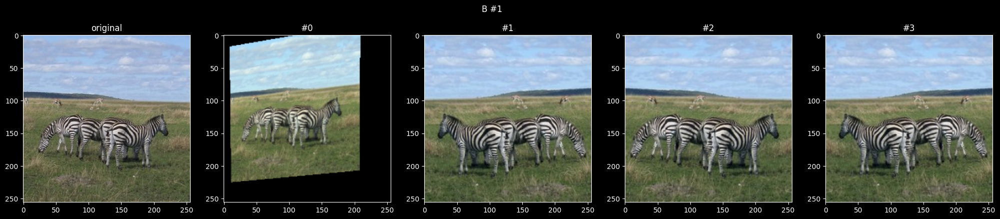

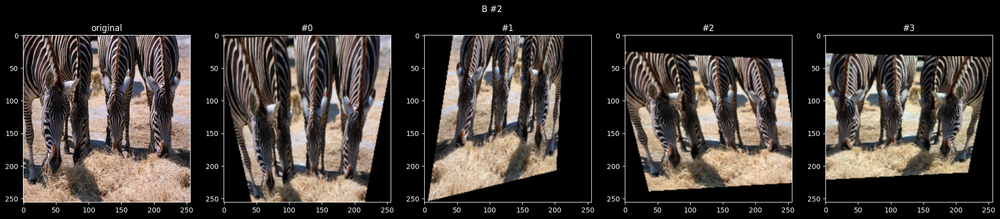

In [5]:
from sklearn.preprocessing import minmax_scale

# Функция для получения train и val transform-ов, а так же функции для де-нормализации изображения
def get_transforms(mean, std):
    train_transform = tr.Compose([
        tr.ToPILImage(),
        tr.RandomHorizontalFlip(0.5),
        tr.RandomPerspective(),
        tr.CenterCrop(224),
        tr.Resize(256),
        tr.ToTensor(),
        tr.Normalize(mean=mean, std=std),
    ])

    val_transform = tr.Compose([
        tr.ToPILImage(),
        tr.CenterCrop(224),
        tr.Resize(256),
        tr.ToTensor(),
        tr.Normalize(mean=mean, std=std),
    ])

    def de_normalize(img, normalized=True):
        if not normalized:
            return img.transpose(1, 2, 0)
        return minmax_scale((img.cpu().numpy().reshape(3, -1) * std[:, None] + mean[:, None]),
                            feature_range=(0., 1.),
                            axis=1).reshape(*img.shape).transpose(1, 2, 0)

    return train_transform, val_transform, de_normalize


train_transform_a, val_transform_a, de_normalize_a = get_transforms(channel_mean_a, channel_std_a)
train_transform_b, val_transform_b, de_normalize_b = get_transforms(channel_mean_b, channel_std_b)


# Функция для визуализации transform-ов
def show_examples(dataset, transform, de_norm, num_per_image=3, image_index=0, title=""):
    fig, ax = plt.subplots(1, 1 + num_per_image, figsize=(5 * (1 + num_per_image), 5))

    image = dataset[image_index]

    plt.suptitle(title, y=0.95)

    plt.subplot(1, 1 + num_per_image, 1)
    plt.imshow(image)
    plt.title("original")

    for i in range(num_per_image):
        plt.subplot(1, 1 + num_per_image, i + 2)
        plt.title(f"#{i}")
        plt.imshow(de_norm(transform(image)))
    plt.show()

# Проверка на адекватность
show_examples(ds.train_a, train_transform_a, de_normalize_a, num_per_image=4, image_index=0, title="A #0")
show_examples(ds.train_a, val_transform_a, de_normalize_a, num_per_image=1, image_index=0, title="A #0 - val")
show_examples(ds.train_a, train_transform_a, de_normalize_a, num_per_image=4, image_index=1, title="A #1")
show_examples(ds.train_a, train_transform_a, de_normalize_a, num_per_image=4, image_index=2, title="A #2")
show_examples(ds.train_b, train_transform_b, de_normalize_b, num_per_image=4, image_index=0, title="B #0")
show_examples(ds.train_b, val_transform_b, de_normalize_b, num_per_image=1, image_index=0, title="B #0 - val")
show_examples(ds.train_b, train_transform_b, de_normalize_b, num_per_image=4, image_index=1, title="B #1")
show_examples(ds.train_b, train_transform_b, de_normalize_b, num_per_image=4, image_index=2, title="B #2")

In [6]:
# Все датасеты с трансформами
ds = DatasetsClass(
    train_a=ImageDatasetNoLabel(
        target_directory / Path("trainA"),
        transforms=train_transform_a,
    ),
    train_b=ImageDatasetNoLabel(
        target_directory / Path("trainB"),
        transforms=val_transform_b,
    ),
    test_a=ImageDatasetNoLabel(
        target_directory / Path("testA"),
        transforms=val_transform_a,
    ),
    test_b=ImageDatasetNoLabel(
        target_directory / Path("testB"),
        transforms=val_transform_b,
    ),
)

## 1.3 DataLoader

In [7]:
@dataclass
class DataLoadersClass:
    train_a: DataLoader
    train_b: DataLoader
    test_a: DataLoader
    test_b: DataLoader

batch_size = 16

dataloaders = DataLoadersClass(
    train_a=DataLoader(
        dataset=ds.train_a,
        batch_size=batch_size,
        shuffle=True,
        drop_last=True,
    ),
    train_b=DataLoader(
        dataset=ds.train_b,
        batch_size=batch_size,
        shuffle=True,
        drop_last=True,
    ),
    test_a=DataLoader(
        dataset=ds.test_a,
        batch_size=batch_size,
        shuffle=False,
        drop_last=True,
    ),
    test_b=DataLoader(
        dataset=ds.test_b,
        batch_size=batch_size,
        shuffle=False,
        drop_last=True,
    ),
)

# 2. Модель (___6 баллов___)

## 2.0 Любые вспомогательные модули и классы

In [8]:
from collections import OrderedDict
from functools import partial

class ResidualBlock(nn.Module):
    def __init__(self, c_in, c_out, kernel_size, do_scale, n_layers=1, activation_class=nn.ReLU, dropout_p=0.3, reverse=False, change_size=0):
        super(ResidualBlock, self).__init__()
        
        self.c_in = c_in
        self.c_out = c_out
        self.kernel_size = kernel_size
        self.n_layers = n_layers
        self.activation_class = activation_class
        self.dropout_p = dropout_p
        self.reverse = reverse
        self.do_scale = do_scale
        self.change_size = change_size
        
        if self.reverse:
            self.conv_class = nn.ConvTranspose2d
            self.scale_class = partial(
                nn.ConvTranspose2d,
                in_channels=self.c_out,
                out_channels=self.c_out,
                stride=2,
            )
            self.conv_name_prefix = "deconv"
            self.scale_name = "upscale"
            self.change_name = "add_size"
        else:
            self.conv_class = nn.Conv2d
            self.scale_class = nn.MaxPool2d
            self.conv_name_prefix = "conv"
            self.scale_name = "downscale"
            self.change_name = "sub_size"
        
        layers = [
            nn.Sequential(OrderedDict([
                (
                    self.conv_name_prefix,
                    self.conv_class(
                        in_channels = self.c_in if i == 0 else self.c_out,
                        out_channels = self.c_out,
                        kernel_size = self.kernel_size,
                        padding = (self.kernel_size - 1) // 2,
                        bias=False,
                    ),
                ),
                ("bnorm", nn.BatchNorm2d(self.c_out)),
                ("act", self.activation_class()),
                ("drop", nn.Dropout2d(self.dropout_p)),
            ])) for i in range(self.n_layers)
        ]
        
        self.layers = nn.Sequential(OrderedDict([(f"layer_{i}", layer) for i, layer in enumerate(layers)]))
        
        self.adapt_residual = nn.Identity() if self.c_in == self.c_out else self.conv_class(self.c_in, self.c_out, 1)
        
        scale = [
            (self.change_name, self.conv_class(self.c_out, self.c_out, self.change_size + 1) if self.change_size > 0 else nn.Identity()),
            (self.scale_name, self.scale_class(kernel_size=2) if self.do_scale else nn.Identity()),
        ]
        self.scale = nn.Sequential(OrderedDict(scale))


    def forward(self, x):
        return self.scale(self.layers(x) + self.adapt_residual(x))

In [9]:
class Discriminator(nn.Module):
    def __init__(self, channels=8, layers=3, kernel_size=3, image_size=256, hidden_size=100):
        super(Discriminator, self).__init__()
        self.blocks = []
        self.blocks += [("initial", ResidualBlock(3, channels, kernel_size, do_scale=False))]

        last_filters_mult = 1
        for i in range(1, layers + 1):
            filters_mult = 2**i
            self.blocks += [(f"block_{i}", ResidualBlock(channels * last_filters_mult, channels * filters_mult, kernel_size, do_scale=True))]
            image_size //= 2
            last_filters_mult = filters_mult

        self.blocks += [("final", ResidualBlock(channels * last_filters_mult, 1, kernel_size, do_scale=True))]
        image_size //= 2
        self.blocks = nn.Sequential(OrderedDict(self.blocks))

        self.pipeline = nn.Sequential(OrderedDict([
            ("flatten", nn.Flatten()),
            ("linear1", nn.Linear(image_size * image_size, hidden_size)),
            ("relu", nn.ReLU()),
            ("linear2", nn.Linear(hidden_size, 1)),
            ("sigmoid", nn.Sigmoid()),
        ]))
    
    def forward(self, images):
        result = self.pipeline(self.blocks(images))
        return result

In [10]:
class Generator(nn.Module):
    def __init__(self, channels=8, kernel_size=3, scales=2, blocks=3):
        super(Generator, self).__init__()
        self.blocks = []
        self.blocks += [("initial", ResidualBlock(3, channels, kernel_size, do_scale=False))]

        last_filters_mult = 1
        for i in range(1, scales + 1):
            filters_mult = 2 * last_filters_mult
            self.blocks += [(f"downscale_{i}", ResidualBlock(channels * last_filters_mult, channels * filters_mult, kernel_size, do_scale=True))]
            last_filters_mult = filters_mult
        
        for i in range(1, blocks + 1):
            self.blocks += [(f"block_{i}", ResidualBlock(channels * last_filters_mult, channels * last_filters_mult, kernel_size, do_scale=False))]
            last_filters_mult = filters_mult
        
        for i in range(1, scales + 1):
            filters_mult = last_filters_mult // 2
            self.blocks += [(f"upscale_{i}", ResidualBlock(channels * last_filters_mult, channels * filters_mult, kernel_size, reverse=True, do_scale=True))]
            last_filters_mult = filters_mult
        
        self.blocks += [("final", ResidualBlock(channels * last_filters_mult, 3, kernel_size, do_scale=False))]
        self.blocks += [("de_pixelize", nn.Conv2d(3, 3, kernel_size * 2 + 1, padding=kernel_size))]

        self.blocks = nn.Sequential(OrderedDict(self.blocks))
        self.norm = nn.Tanh()
    
    def forward(self, images):
        return self.norm(self.blocks(images))

## 2.1 Архитектура сети (___3 балла___)

In [11]:
class CycleGAN(nn.Module):
    def __init__(self):
        super(CycleGAN, self).__init__()
        self.gen_a_b = Generator()
        self.gen_b_a = Generator()
        self.discr_a = Discriminator()
        self.discr_b = Discriminator()
    
    def forward(self, images_a, images_b):
        pred_true_a = self.discr_a(images_a)
        pred_true_b = self.discr_b(images_b)
        
        (images_a, images_b) = self.gen_b_a(images_b), self.gen_a_b(images_a)

        pred_fake_a = self.discr_a(images_a)
        pred_fake_b = self.discr_b(images_b)

        (cycled_a, cycled_b) = self.gen_b_a(images_b), self.gen_a_b(images_a)

        return pred_true_a, pred_true_b, pred_fake_a, pred_fake_b, cycled_a, cycled_b

    def get_fake_a(self, images_b):
        with torch.no_grad():
            return self.gen_a_b(images_b)
    
    def get_fake_b(self, images_a):
        with torch.no_grad():
            return self.gen_b_a(images_a)

## 2.2 Loss (___3 балла___)

$$ \mathbf{L}_{\text{cyc}} \big( G_{A \rightarrow B}, G_{B \rightarrow A} \big) = \mathbb{E}_{a \sim A} \bigg( \Big\| G_{B \rightarrow A} \big( G_{A \rightarrow B} ( a ) \big) - a \Big\|_1 \bigg) + \mathbb{E}_{b \sim B} \bigg( \Big\| G_{A \rightarrow B} \big( G_{B \rightarrow A} ( b ) \big) - b \Big\|_1 \bigg) \longrightarrow \min_{G}$$

In [12]:
class CycleConsistencyLoss(nn.Module):
    def __init__(self):
        super(CycleConsistencyLoss, self).__init__()
        self.loss = nn.L1Loss(reduce=True, reduction='mean')
    
    def forward(self, initial, cycled):
        return self.loss(initial, cycled)

$$ \mathbf{L}_{\text{GAN}} \big( G_{A \rightarrow B}, D_{B} \big) = \mathbb{E}_{b \sim B} \log D_{B} (b) + \mathbb{E}_{a \sim A} \log \Big( 1 - D_{B} \big( G_{A \rightarrow B} (a) \big) \Big) \longrightarrow \min_{G} \max_{D}$$

In [13]:
class AdversarialLossCE(nn.Module):
    """
    Стандартная функция ошибки для minmax игры GAN-ов
    """
    def __init__(self):
        super(AdversarialLossCE, self).__init__()
    
    def forward(self, pred, is_fake=False):
        # Принимает на вход D_{A}(a) - real_pred
        if is_fake:
            pred = 1 - pred
        return torch.mean(torch.log(pred))

$$ \mathbb{E}_{b \sim B} \big( D_{B} (b) - 1 \big)^2 + \mathbb{E}_{a \sim A} \Big( D_{B} \big( G_{A \rightarrow B} (a) \big) \Big)^2 \longrightarrow \min_{D} $$
$$ \mathbb{E}_{a \sim A} \Big( D_{B} \big( G_{A \rightarrow B} (a) \big) - 1 \Big)^2 \longrightarrow \min_{G} $$

In [14]:
class AdversarialLossMSE(nn.Module):
    """
    Можно переписать не через CE, а через MSE loss на одном предсказании, помогает со стабильностью
    """
    def __init__(self):
        super(AdversarialLossMSE, self).__init__()

    def forward(self, pred, is_fake=False):
        # Принимает на вход D_{A}(a) - real_pred
        if is_fake:
            pred = 1 - pred
        return torch.mean(torch.square(1 - pred))

$$ \mathbf{L} \big( G_{A \rightarrow B}, G_{B \rightarrow A}, D_{A}, D_{B} \big) = \mathbf{L}_{\text{GAN}} \big( G_{A \rightarrow B}, D_{B} \big) + \mathbf{L}_{\text{GAN}} \big( G_{B \rightarrow A}, D_{A} \big) + \lambda \cdot \mathbf{L}_{\text{cyc}} \big( G_{A \rightarrow B}, G_{B \rightarrow A} \big) \longrightarrow \min_{G} \max_{D}$$

In [15]:
class FullDiscriminatorLoss(nn.Module):
    """
    Полная ошибка для дискриминатора
    """
    def __init__(self, is_mse=True):
        super(FullDiscriminatorLoss, self).__init__()
        self.adversarial_loss_func = AdversarialLossMSE() if is_mse else AdversarialLossCE()
    
    def forward(self, pred, is_fake=False):
        return self.adversarial_loss_func(pred, is_fake)

In [16]:
class FullGeneratorLoss(nn.Module):
    """
    Полная ошибка для генератора
    """
    def __init__(self, lambda_value=10., is_mse=True):
        super(FullGeneratorLoss, self).__init__()
        self.adversarial_loss_func = AdversarialLossMSE() if is_mse else AdversarialLossCE()
        self.cycle_consistency_loss_func = CycleConsistencyLoss()
        self.lambda_value = lambda_value
    
    def forward(
        self,
        initial_a,
        b_from_a_discr_pred,
        a_cycled,
    ):
        return self.cycle_consistency_loss_func(initial_a, a_cycled) * self.lambda_value + self.adversarial_loss_func(b_from_a_discr_pred)

# 3. Подготовка обучения (__2 балла__)

## 3.1 Шаг обучения генератора

In [17]:
def train_generators_batch(model, opt_g, imgs_a, imgs_b, gen_loss_fn):
    model.train()

    opt_g.zero_grad()

    _, _, preds_fake_a, preds_fake_b, cycled_a, cycled_b = model(imgs_a, imgs_b)

    loss_g = gen_loss_fn(imgs_a, preds_fake_a, cycled_a) + gen_loss_fn(imgs_b, preds_fake_b, cycled_b)

    loss_g.backward()

    opt_g.step()
    
    return model, opt_g, loss_g.item()

## 3.2 Шаг обучения дискриминатора

In [18]:
def train_discriminators_batch(model, opt_d, imgs_a, imgs_b, discr_loss_fn):
    model.train()

    opt_d.zero_grad()

    preds_true_a, preds_true_b, preds_fake_a, preds_fake_b, _, _ = model(imgs_a, imgs_b)
    
    loss_d = discr_loss_fn(preds_true_a) + discr_loss_fn(preds_true_b) - discr_loss_fn(preds_fake_a) - discr_loss_fn(preds_fake_b)
    
    loss_d.backward(retain_graph=True)

    opt_d.step()

    opt_d.zero_grad()
    
    return model, opt_d, loss_d.item()

## 3.3 Шаг валидации

In [19]:
from collections import defaultdict

def val(model, loader_a, loader_b, discr_loss_fn, gen_loss_fn):
    model.eval()
    
    val_data = defaultdict(list)

    with torch.no_grad():
        for (imgs_a, imgs_b) in tqdm(zip(loader_a, loader_b)):
            imgs_a = imgs_a.to(device)
            imgs_b = imgs_b.to(device)
            
            a_real_pred, b_real_pred, a_fake_pred, b_fake_pred, cycled_a, cycled_b = model(imgs_a, imgs_b)
            
            loss_d = discr_loss_fn(a_real_pred) + discr_loss_fn(b_real_pred) - discr_loss_fn(a_fake_pred) - discr_loss_fn(b_fake_pred)
            
            loss_g = gen_loss_fn(imgs_a, a_fake_pred, cycled_a) + gen_loss_fn(imgs_b, b_fake_pred, cycled_b)
            
            val_data["loss D"].append(loss_d.item())
            val_data["loss G"].append(loss_g.item())

            val_data["real pred A"].extend(a_real_pred[:, 0].cpu().detach().tolist())
            val_data["real pred B"].extend(b_real_pred[:, 0].cpu().detach().tolist())
            val_data["fake pred A"].extend(a_fake_pred[:, 0].cpu().detach().tolist())
            val_data["fake pred B"].extend(b_fake_pred[:, 0].cpu().detach().tolist())
        
        val_data["loss D"] = np.mean(val_data["loss D"])
        val_data["loss G"] = np.mean(val_data["loss G"])
    
    return val_data

## 3.4 Визуализация сгенерированного

In [20]:
def draw_imgs(model, num_images, loader_a, loader_b, de_norm_a, de_norm_b):
    model.eval()
    with torch.no_grad():
        imgs_a = next(iter(loader_a))[:num_images].to(device)
        imgs_b = next(iter(loader_b))[:num_images].to(device)
        
        fake_a = model.get_fake_a(imgs_b)
        fake_b = model.get_fake_b(imgs_a)
        rec_a = model.get_fake_a(fake_b)
        rec_b = model.get_fake_b(fake_a)
        
        # Draw num_images examples for A
        fig, ax = plt.subplots(num_images, 3, figsize=(25, 15))
        plt.suptitle("Images from A", y=0.92)
        
        for ind in range(num_images):
            plt.subplot(num_images, 3, ind * 3 + 1)
            plt.title("Original from A")
            plt.imshow(de_norm_a(imgs_a[ind], normalized=True))
            plt.xticks([])
            plt.yticks([])
            
            plt.subplot(num_images, 3, ind * 3 + 2)
            plt.title("Translated to B")
            plt.imshow(de_norm_b(fake_b[ind], normalized=True))
            plt.xticks([])
            plt.yticks([])
            
            plt.subplot(num_images, 3, ind * 3 + 3)
            plt.title("Reconstructed A")
            plt.imshow(de_norm_a(rec_a[ind], normalized=True))
            plt.xticks([])
            plt.yticks([])
        
        # Draw num_images examples for B
        fig, ax = plt.subplots(num_images, 3, figsize=(25, 15))
        plt.suptitle("Images from B", y=0.92)
        
        for ind in range(num_images):
            plt.subplot(num_images, 3, ind * 3 + 1)
            plt.title("Original from B")
            plt.imshow(de_norm_b(imgs_b[ind], normalized=True))
            plt.xticks([])
            plt.yticks([])
            
            plt.subplot(num_images, 3, ind * 3 + 2)
            plt.title("Translated to A")
            plt.imshow(de_norm_a(fake_a[ind], normalized=True))
            plt.xticks([])
            plt.yticks([])
            
            plt.subplot(num_images, 3, ind * 3 + 3)
            plt.title("Reconstructed B")
            plt.imshow(de_norm_b(rec_b[ind], normalized=True))
            plt.xticks([])
            plt.yticks([])
    
        plt.show()

## 3.5 Цикл обучения

In [21]:
from IPython.display import clear_output
import warnings

def get_model_name(chkp_folder, model_name=None):
    # Выбираем имя чекпоинта для сохранения
    if model_name is None:
        if os.path.exists(chkp_folder):
            num_starts = len(os.listdir(chkp_folder)) + 1
        else:
            num_starts = 1
        model_name = f'model#{num_starts}'
    else:
        if "#" not in model_name:
            model_name += "#0"
    changed = False
    while os.path.exists(os.path.join(chkp_folder, model_name + '.pt')):
        model_name, ind = model_name.split("#")
        model_name += f"#{int(ind) + 1}"
        changed=True
    if changed:
        warnings.warn(f"Selected model_name was used already! To avoid possible overwrite - model_name changed to {model_name}")
    return model_name


def get_lr(optimizer):
    for param_group in optimizer.param_groups:
        return param_group['lr']


def learning_loop(
    model,
    optimizer_g,
    optimizer_d,
    train_loader_a,
    train_loader_b,
    val_loader_a,
    val_loader_b,
    criterion_d,
    criterion_g,
    de_norm_a,
    de_norm_b,
    scheduler_d=None,
    scheduler_g=None,
    min_lr=None,
    epochs=10,
    val_every=1,
    draw_every=1,
    model_name=None,
    chkp_folder="./chkps",
    images_per_validation=3,
    plots=None,
    starting_epoch=0,
):
    model_name = get_model_name(chkp_folder, model_name)
    
    if plots is None:
        plots = {
            'train G': [],
            'train D': [],
            'val D': [],
            'val G': [],
            "lr G": [],
            "lr D": [],
            "hist real A": [],
            "hist gen A": [],
            "hist real B": [],
            "hist gen B": [],
        }

    for epoch in np.arange(1, epochs+1) + starting_epoch:
        print(f'#{epoch}/{epochs}:')

        plots['lr G'].append(get_lr(optimizer_g))
        plots['lr D'].append(get_lr(optimizer_d))
        
        losses_d = []
        losses_g = []

        for (imgs_a, imgs_b) in tqdm(zip(train_loader_a, train_loader_b), total=min(len(ds.train_a), len(ds.train_b)) // batch_size):
            imgs_a = imgs_a.to(device)
            imgs_b = imgs_b.to(device)
            model, optimizer_d, loss_d = train_discriminators_batch(model, optimizer_d, imgs_a, imgs_b, criterion_d)
            model, optimizer_g, loss_g = train_generators_batch(model, optimizer_g, imgs_a, imgs_b, criterion_g)
            losses_d.append(float(loss_d))
            losses_g.append(float(loss_g))

        loss_d = np.mean(np.array(losses_d))
        loss_g = np.mean(np.array(losses_g))
        
        plots['train D'].extend([loss_d])
        plots['train G'].extend([loss_g])

        if not (epoch % val_every):
            print("validate")
            val_data = val(model, val_loader_a, val_loader_b, criterion_d, criterion_g)
            plots['val D'].append(val_data["loss D"])
            plots['val G'].append(val_data["loss G"])
            plots['hist real A'].append(val_data["real pred A"])
            plots['hist gen A'].append(val_data["fake pred A"])
            plots['hist real B'].append(val_data["real pred B"])
            plots['hist gen B'].append(val_data["fake pred B"])
            
            # Сохраняем модель
            if not os.path.exists(chkp_folder):
                os.makedirs(chkp_folder)
            torch.save(
                {
                    'epoch': epoch,
                    'model_state_dict': model.state_dict(),
                    'optimizer_d_state_dict': optimizer_d.state_dict(),
                    'optimizer_g_state_dict': optimizer_g.state_dict(),
                    'scheduler_d_state_dict': scheduler_d.state_dict(),
                    'scheduler_g_state_dict': scheduler_g.state_dict(),
                    'plots': plots,
                },
                os.path.join(chkp_folder, model_name + '.pt'),
            )
            
            # Шедулинг
            if scheduler_d:
                try:
                    scheduler_d.step()
                except:
                    scheduler_d.step(loss_d)
            if scheduler_g:
                try:
                    scheduler_g.step()
                except:
                    scheduler_g.step(loss_g)

        if not (epoch % draw_every):
            clear_output(True)
            
            hh = 2
            ww = 2
            plt_ind = 1
            fig, ax = plt.subplots(hh, ww, figsize=(25, 12))
            fig.suptitle(f'#{epoch}/{epochs}:')

            plt.subplot(hh, ww, plt_ind)
            plt.title('discriminators losses')
            plt.plot(np.arange(1, epoch + 1), plots['train D'], 'r.-', label='train', alpha=0.7)
            plt.plot(np.arange(1, epoch + 1), plots['val D'], 'g.-', label='val', alpha=0.7)
            plt.grid()
            plt.legend()
            plt_ind += 1
            
            plt.subplot(hh, ww, plt_ind)
            plt.title('generators losses')
            plt.plot(np.arange(1, epoch + 1), plots['train G'], 'r.-', label='train', alpha=0.7)
            plt.plot(np.arange(1, epoch + 1), plots['val G'], 'g.-', label='val', alpha=0.7)
            plt.grid()
            plt.legend()
            plt_ind += 1
            
            # plt.subplot(hh, ww, plt_ind)
            # plt.title('learning rates')
            # plt.plot(plots["lr D"], 'b.-', label='lr discriminator', alpha=0.7)
            # plt.plot(plots["lr G"], 'm.-', label='lr generator', alpha=0.7)
            # plt.legend()
            # plt_ind += 1
            
            plt.subplot(hh, ww, plt_ind)
            plt.title("Discriminator A predictions")
            plt.hist(plots["hist real A"][-1], bins=50, density=True, label="real", color="green", alpha=0.7)
            plt.hist(plots["hist gen A"][-1], bins=50, density=True, label="generated", color="red", alpha=0.7)
            plt.xlim((-0.05, 1.05))
            plt.xticks(ticks=np.arange(0, 1.05, 0.1))
            plt.legend()
            plt_ind += 1
            
            plt.subplot(hh, ww, plt_ind)
            plt.title("Discriminator B predictions")
            plt.hist(plots["hist real B"][-1], bins=50, density=True, label="real", color="green", alpha=0.7)
            plt.hist(plots["hist gen B"][-1], bins=50, density=True, label="generated", color="red", alpha=0.7)
            plt.xlim((-0.05, 1.05))
            plt.xticks(ticks=np.arange(0, 1.05, 0.1))
            plt.legend()
            plt_ind += 1
            
            plt.show()
            
            draw_imgs(model, images_per_validation, val_loader_a, val_loader_b, de_norm_a, de_norm_b)
                
        
        if min_lr and get_lr(optimizer_d) <= min_lr:
            print(f'Learning process ended with early stop for discriminator after epoch {epoch}')
            break
        
        if min_lr and get_lr(optimizer_g) <= min_lr:
            print(f'Learning process ended with early stop for generator after epoch {epoch}')
            break
    
    return model, optimizer_d, optimizer_g, plots

# 4. Обучение (___2 балла___)

## 4.1 Инициализация модели и оптимайзера

In [22]:
from collections import defaultdict
from termcolor import colored


def beautiful_int(i):
    i = str(i)
    return ".".join(reversed([i[max(j, 0):j+3] for j in range(len(i) - 3, -3, -3)]))


# Подсчёт числа параметров в нашей модели
def model_num_params(model, verbose_all=True, verbose_only_learnable=False):
    sum_params = 0
    sum_learnable_params = 0
    submodules = defaultdict(lambda : [0, 0])
    for name, param in model.named_parameters():
        num_params = param.numel()
        if verbose_all or (verbose_only_learnable and param.requires_grad):
            print(
                colored(
                    '{: <65} ~  {: <9} params ~ grad: {}'.format(
                        name,
                        beautiful_int(num_params),
                        param.requires_grad,
                    ),
                    {True: "green", False: "red"}[param.requires_grad],
                )
            )
        sum_params += num_params
        sm = name.split(".")[0]
        submodules[sm][0] += num_params
        if param.requires_grad:
            sum_learnable_params += num_params
            submodules[sm][1] += num_params
    print(
        f'\nIn total:\n  - {beautiful_int(sum_params)} params\n  - {beautiful_int(sum_learnable_params)} learnable params'
    )
    
    for sm, v in submodules.items():
        print(
            f"\n . {sm}:\n .   - {beautiful_int(submodules[sm][0])} params\n .   - {beautiful_int(submodules[sm][1])} learnable params"
        )
    return sum_params, sum_learnable_params

In [23]:
device = torch.device('cuda:0') if torch.cuda.is_available() else torch.device('cpu')

def create_model_and_optimizer(model_class, model_params, lr=1e-3, device=device):
    model = model_class(**model_params)
    model = model.to(device)
    
    optimizer_g = torch.optim.AdamW(
        list(model.gen_a_b.parameters()) + list(model.gen_b_a.parameters()),
        lr,
    )
    optimizer_d = torch.optim.AdamW(
        list(model.discr_a.parameters()) + list(model.discr_b.parameters()),
        lr,
    )
    return model, optimizer_d, optimizer_g

## 4.2 Фактическое обучение

In [24]:
device = torch.device('cuda:0') if torch.cuda.is_available() else torch.device('cpu')

results = []

model, optimizer_d, optimizer_g = create_model_and_optimizer(
    model_class = CycleGAN,
    model_params = {},
    lr = 1e-3,
    device = device,
)


scheduler_d = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer_d)
scheduler_g = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer_g)

criterion_d = FullDiscriminatorLoss(True)
criterion_g = FullGeneratorLoss(0.5, True)

sum_params, sum_learnable_params = model_num_params(model)

gen_a_b.blocks.initial.layers.layer_0.conv.weight                 ~  216       params ~ grad: True
gen_a_b.blocks.initial.layers.layer_0.bnorm.weight                ~  8         params ~ grad: True
gen_a_b.blocks.initial.layers.layer_0.bnorm.bias                  ~  8         params ~ grad: True
gen_a_b.blocks.initial.adapt_residual.weight                      ~  24        params ~ grad: True
gen_a_b.blocks.initial.adapt_residual.bias                        ~  8         params ~ grad: True
gen_a_b.blocks.downscale_1.layers.layer_0.conv.weight             ~  1.152     params ~ grad: True
gen_a_b.blocks.downscale_1.layers.layer_0.bnorm.weight            ~  16        params ~ grad: True
gen_a_b.blocks.downscale_1.layers.layer_0.bnorm.bias              ~  16        params ~ grad: True
gen_a_b.blocks.downscale_1.adapt_residual.weight                  ~  128       params ~ grad: True
gen_a_b.blocks.downscale_1.adapt_residual.bias                    ~  16        params ~ grad: True
gen_a_b.bl

/home/gleb/PythonVenvs/venv/lib/python3.14/site-packages/torch/nn/modules/loss.py:44: UserWarning: size_average and reduce args will be deprecated, please use reduction='mean' instead.
  self.reduction: str = _Reduction.legacy_get_string(size_average, reduce)


In [25]:
model

CycleGAN(
  (gen_a_b): Generator(
    (blocks): Sequential(
      (initial): ResidualBlock(
        (layers): Sequential(
          (layer_0): Sequential(
            (conv): Conv2d(3, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
            (bnorm): BatchNorm2d(8, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
            (act): ReLU()
            (drop): Dropout2d(p=0.3, inplace=False)
          )
        )
        (adapt_residual): Conv2d(3, 8, kernel_size=(1, 1), stride=(1, 1))
        (scale): Sequential(
          (sub_size): Identity()
          (downscale): Identity()
        )
      )
      (downscale_1): ResidualBlock(
        (layers): Sequential(
          (layer_0): Sequential(
            (conv): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
            (bnorm): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
            (act): ReLU()
            (drop): Dropout2d(p=0.3, i

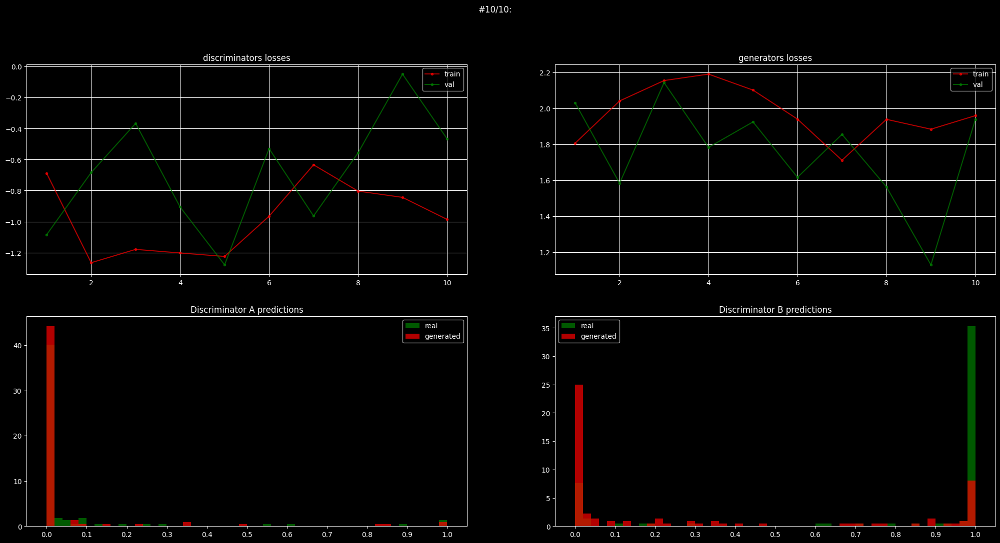

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.0000000000000002].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.0000000000000002].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.0000000000000002].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.0000000000000002].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.0000000000000002].


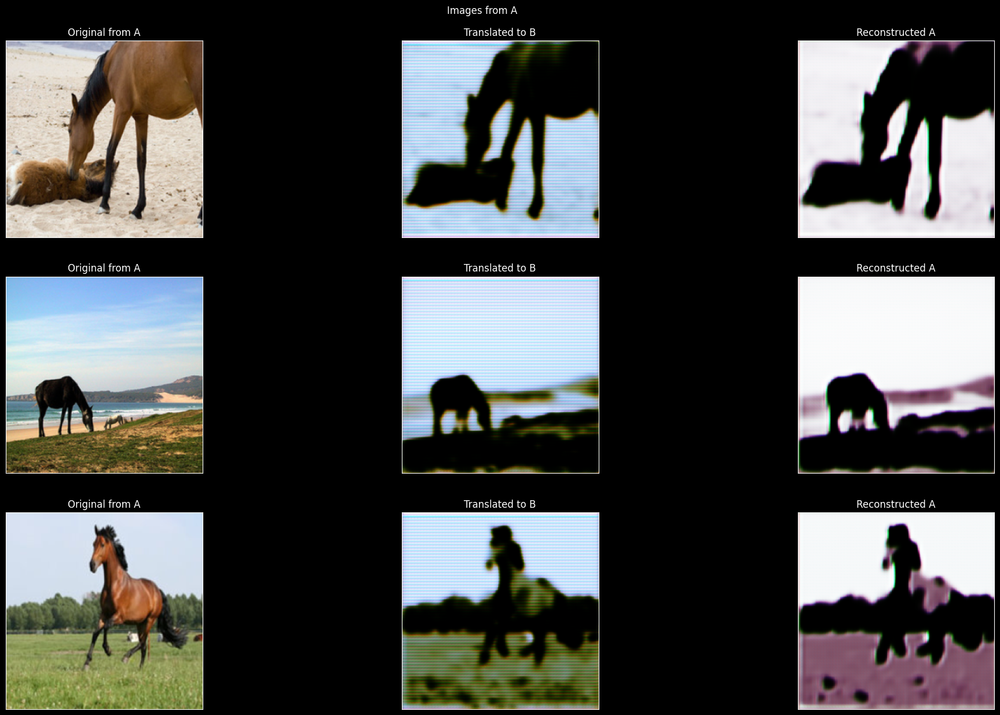

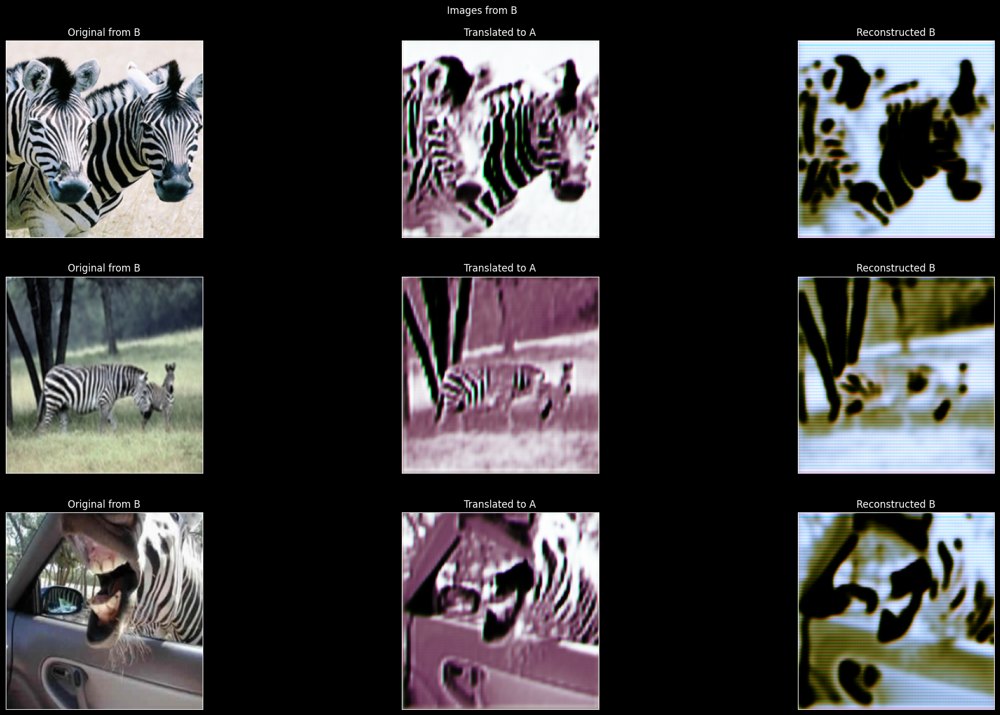

In [26]:
model, optimizer_d, optimizer_g, plots = learning_loop(
    model = model,
    optimizer_g = optimizer_g,
    optimizer_d = optimizer_d,
    train_loader_a = dataloaders.train_a,
    train_loader_b = dataloaders.train_b,
    val_loader_a = dataloaders.test_a,
    val_loader_b = dataloaders.test_b,
    criterion_d = criterion_d,
    criterion_g = criterion_g,
    scheduler_g = scheduler_g,
    scheduler_d = scheduler_d,
    de_norm_a = de_normalize_a,
    de_norm_b = de_normalize_b,
    epochs = 10,
    min_lr = 1e-6,
    val_every = 1,
    draw_every = 1,
    chkp_folder = "./chkp",
    model_name = "cycle_gan",
    images_per_validation=3,
    plots=None,
    starting_epoch=0,
)

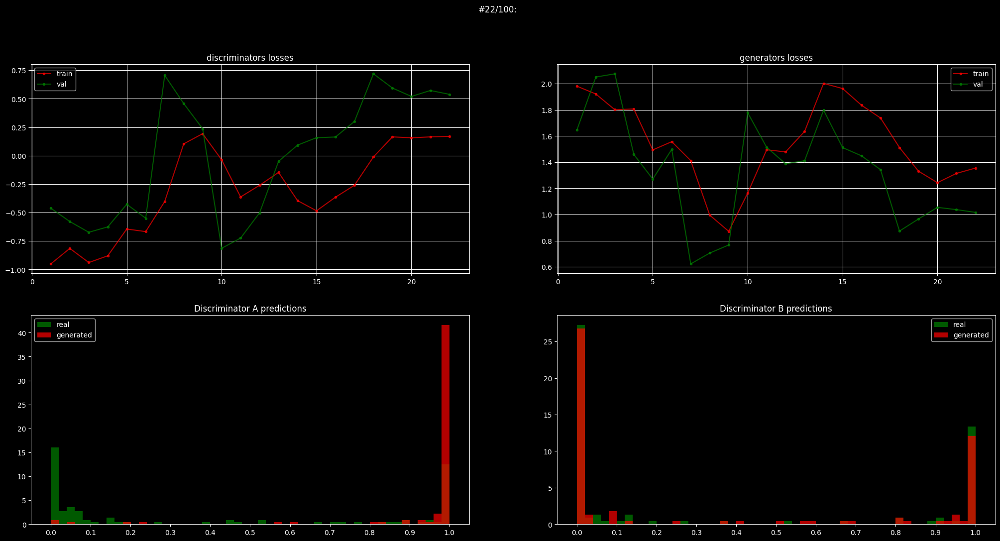

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.0000000000000002].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.0000000000000002].


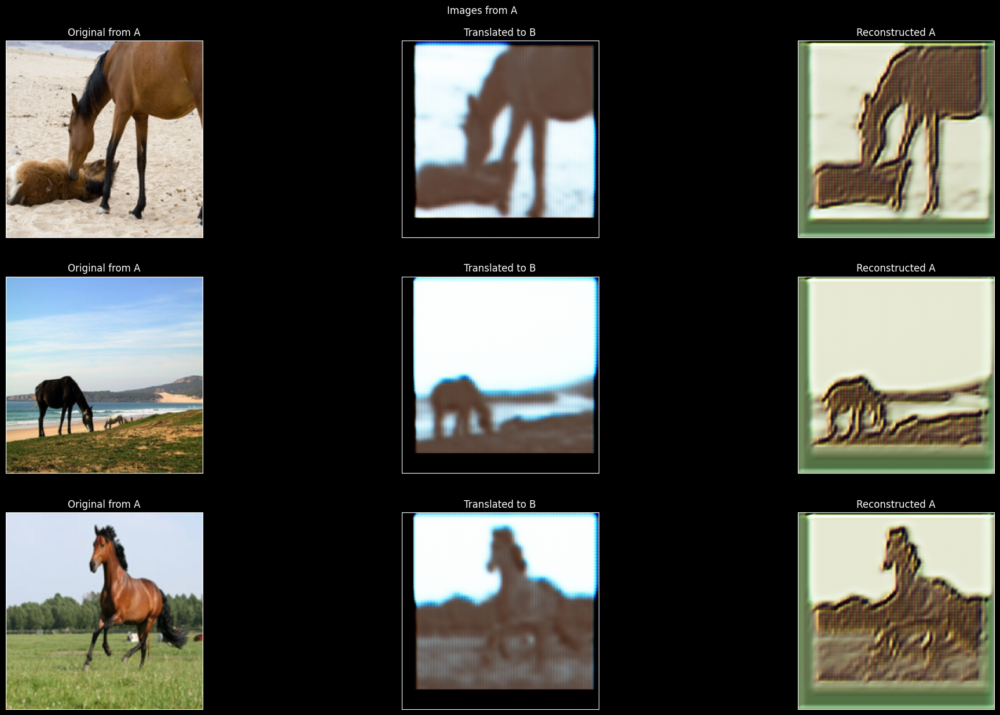

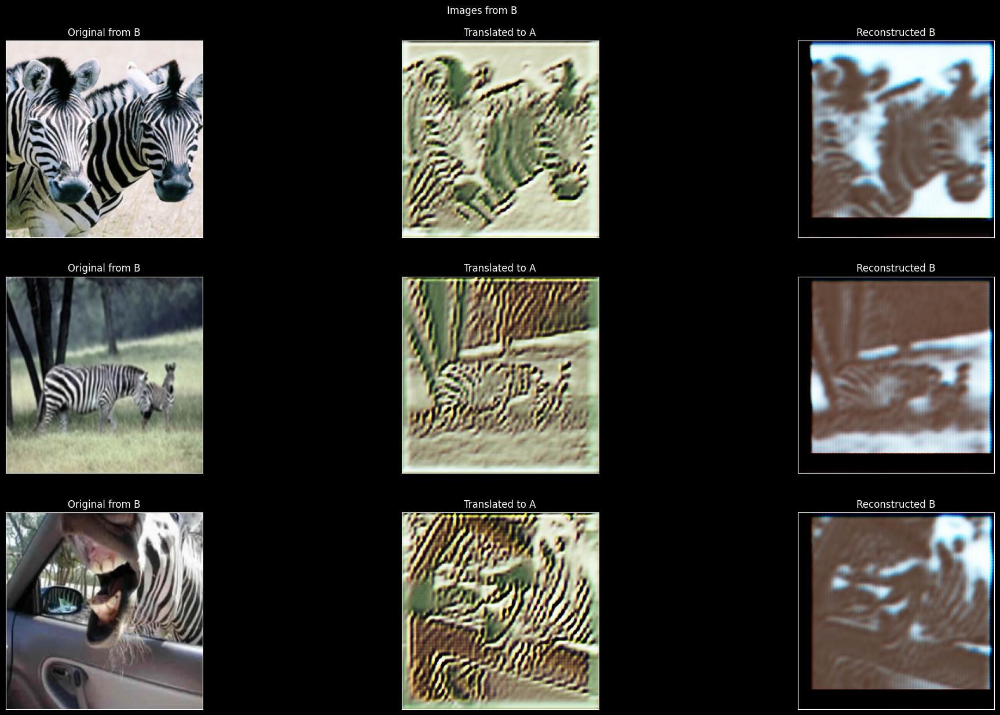

#23/100:


  0%|          | 0/66 [00:00<?, ?it/s]

In [ ]:
model, optimizer_d, optimizer_g, plots = learning_loop(
    model = model,
    optimizer_g = optimizer_g,
    optimizer_d = optimizer_d,
    train_loader_a = dataloaders.train_a,
    train_loader_b = dataloaders.train_b,
    val_loader_a = dataloaders.test_a,
    val_loader_b = dataloaders.test_b,
    criterion_d = criterion_d,
    criterion_g = criterion_g,
    scheduler_g = scheduler_g,
    scheduler_d = scheduler_d,
    de_norm_a = de_normalize_a,
    de_norm_b = de_normalize_b,
    epochs = 100,
    min_lr = 1e-6,
    val_every = 1,
    draw_every = 1,
    chkp_folder = "./chkp",
    model_name = "cycle_gan",
    images_per_validation=3,
    plots=None,
    starting_epoch=0,
)

In [27]:
model.eval()

CycleGAN(
  (gen_a_b): Generator(
    (blocks): Sequential(
      (initial): ResidualBlock(
        (layers): Sequential(
          (layer_0): Sequential(
            (conv): Conv2d(3, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
            (bnorm): BatchNorm2d(8, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
            (act): ReLU()
            (drop): Dropout2d(p=0.3, inplace=False)
          )
        )
        (adapt_residual): Conv2d(3, 8, kernel_size=(1, 1), stride=(1, 1))
        (scale): Sequential(
          (sub_size): Identity()
          (downscale): Identity()
        )
      )
      (downscale_1): ResidualBlock(
        (layers): Sequential(
          (layer_0): Sequential(
            (conv): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
            (bnorm): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
            (act): ReLU()
            (drop): Dropout2d(p=0.3, i

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.0000000000000002].


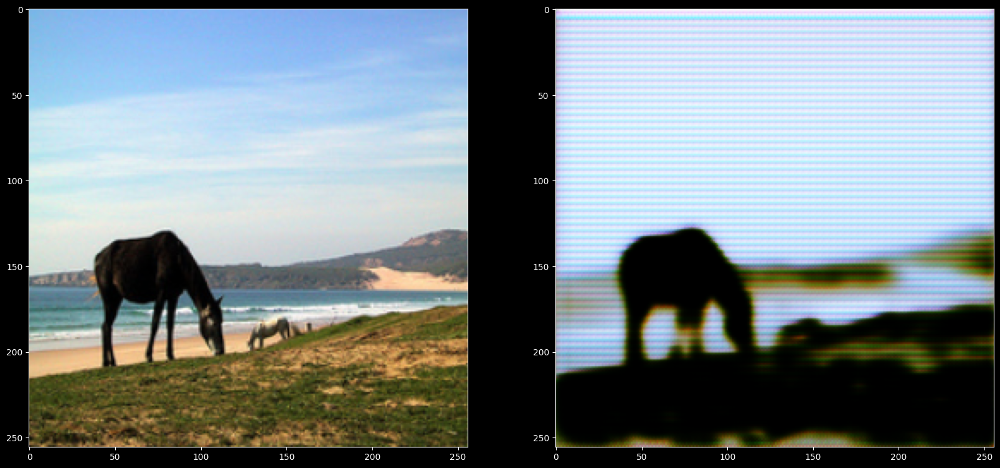

In [29]:
img_a = ds.test_a[1].to(device).unsqueeze(0)

plt.subplots(1, 2, figsize=(20, 10))

plt.subplot(121)
plt.imshow(de_normalize_a(img_a[0]))

plt.subplot(122)
plt.imshow(de_normalize_b(model.get_fake_b(img_a)[0]))

plt.show()

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.0000000000000002].


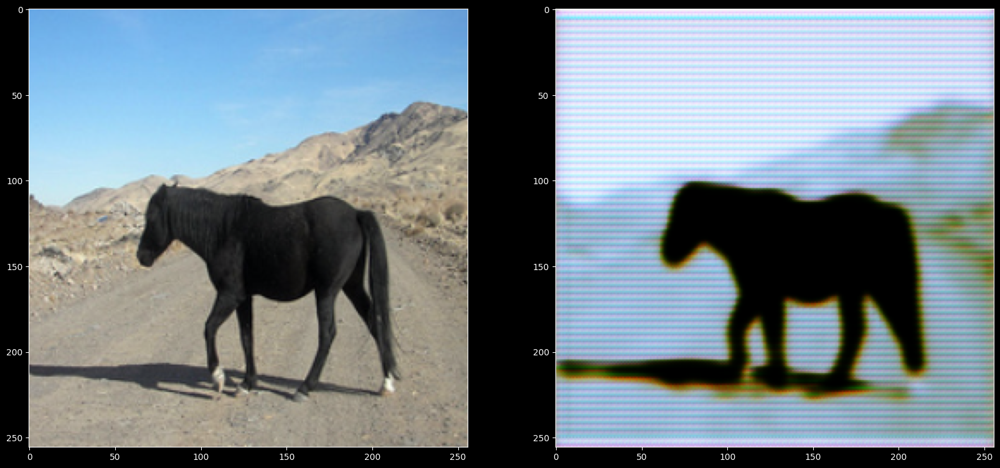

In [30]:
img_a = ds.test_a[5].to(device).unsqueeze(0)

plt.subplots(1, 2, figsize=(20, 10))

plt.subplot(121)
plt.imshow(de_normalize_a(img_a[0]))

plt.subplot(122)
plt.imshow(de_normalize_b(model.get_fake_b(img_a)[0]))

plt.show()

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.0000000000000002].


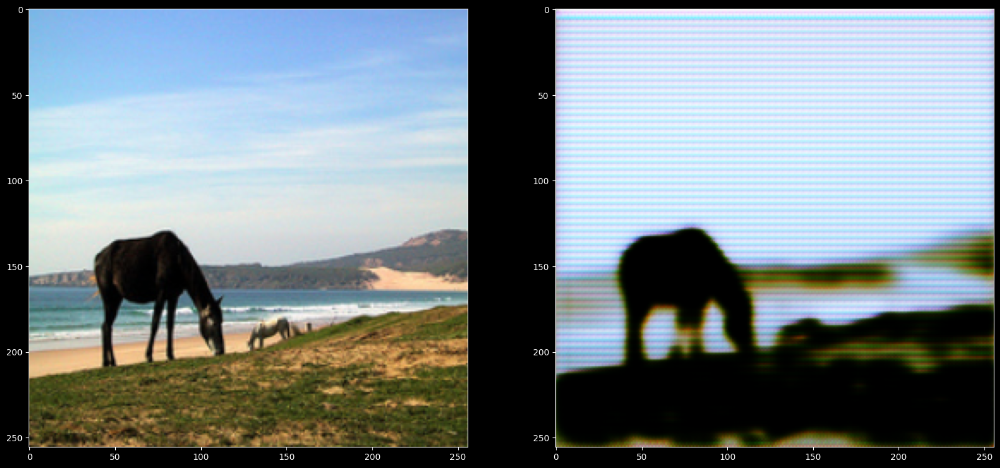

In [35]:
img_ind = 1
img_a = ds.test_a[img_ind].to(device).unsqueeze(0)
fake_b = model.get_fake_b(img_a)

plt.subplots(1, 2, figsize=(20, 10))

plt.subplot(121)
plt.imshow(de_normalize_a(img_a[0]))

plt.subplot(122)
plt.imshow(de_normalize_b(fake_b[0]))

plt.show()

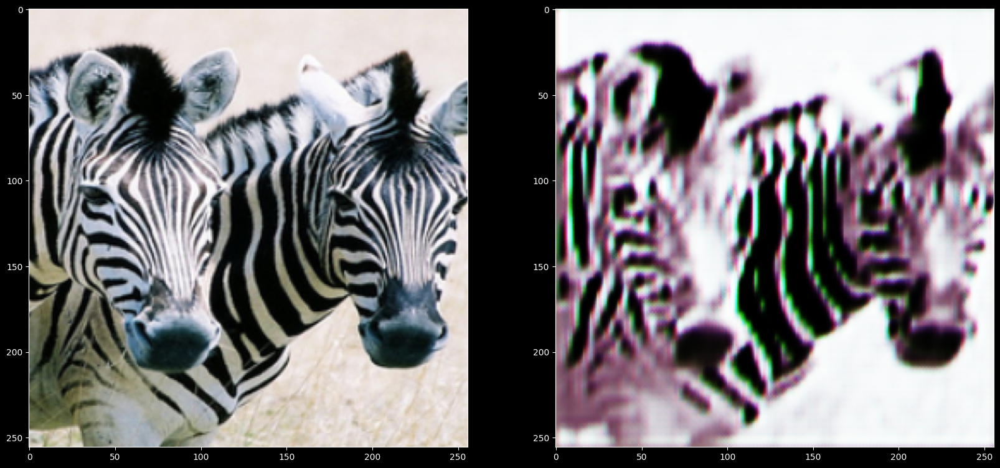

In [36]:
img_ind = 0
img_b = ds.test_b[img_ind].to(device).unsqueeze(0)
fake_a = model.get_fake_a(img_b)

plt.subplots(1, 2, figsize=(20, 10))

plt.subplot(121)
plt.imshow(de_normalize_b(img_b[0]))

plt.subplot(122)
plt.imshow(de_normalize_a(fake_a[0]))

plt.show()

# 5. Свои данные (___3 балла + бонусы___)

В этой части необходимо выполнить следующее:

1. **Создание датасетов**  
   * Соберите один или пару небольших датасета (минимум 100 примеров, но чем больше, тем лучше).  
   * Дайте волю фантазии, но избегайте неадекватного контента, объема данных или данных за рамками норм.  

2. **Обучение CycleGAN**  
   * Обучите модель CycleGAN для преобразования между вашим датасетом (**домен A**) и другим датасетом (**домен B**).  
   * Второй датасет может быть вашим собственным или любым существующим  

3. **Требования к сдаче**  
   * **Архив с датасетами**:  
     Приложите ссылку на заархивированные данные или загрузите сам архив с данными, использованные для обучения.  
   * **Jupyter Notebook**:  
     * Визуализируйте примеры из доменов A и B с кратким описанием идеи (например, "преобразование эскизов в цветные рисунки").  
     * Добавьте код обучения модели (архитектура, гиперпараметры, функция потерь).  
     * Покажите результаты работы модели (минимум по 5 примеров преобразований A→B и B→A).  
   * **Hugging Face Space + Streamlit**:  
     * Разработайте интерактивное приложение с использованием Streamlit, которое позволяет:  
       - Загружать изображения из доменов A и B.  
       - Отображать результаты преобразований (A→B и B→A) в реальном времени.  
     * Выложите приложение в Hugging Face Space и приложите ссылку на него.  
     * Убедитесь, что модель интегрирована в приложение, а проверяющие могут самостоятельно тестировать её через интерфейс.  

4. **Критерии оценки**  
   * Дополнительные баллы начисляются за:  
     - Креативные и качественные датасеты.  
     - Высокое качество преобразований (четкость, сохранение структуры, отсутствие артефактов).  
     - Удобный и наглядный интерфейс Streamlit-приложения.  

**Примеры идей для датасетов**:  
- Эскизы → Реалистичные изображения.  
- Дневные фото → Ночные фото.  
- Картины в стиле импрессионизма → фотореализм.  

**Важно**:  
- Проверяющий будет оценивать работу через ваше Streamlit-приложение. Убедитесь, что инференс работает стабильно.  
- Если модель слишком велика для деплоя, используйте оптимизацию.  

___Удачи!___ 🚀